In [23]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import plotly.express as px
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy.stats import shapiro
import statsmodels.formula.api as smf

%matplotlib inline

In [69]:
# cancer data
pathData = "/home/jkalami/Documents/schulenArbeiten/statisticalMethods/datasets/cancer.csv"
data = pd.read_csv(pathData)
data['diagnosis_binary'] = data['diagnosis'].map({'M': 1, 'B': 0})
data.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,diagnosis_binary
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [70]:
columns = data.columns
columns

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'diagnosis_binary'],
      dtype='object')

In [71]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

<Axes: >

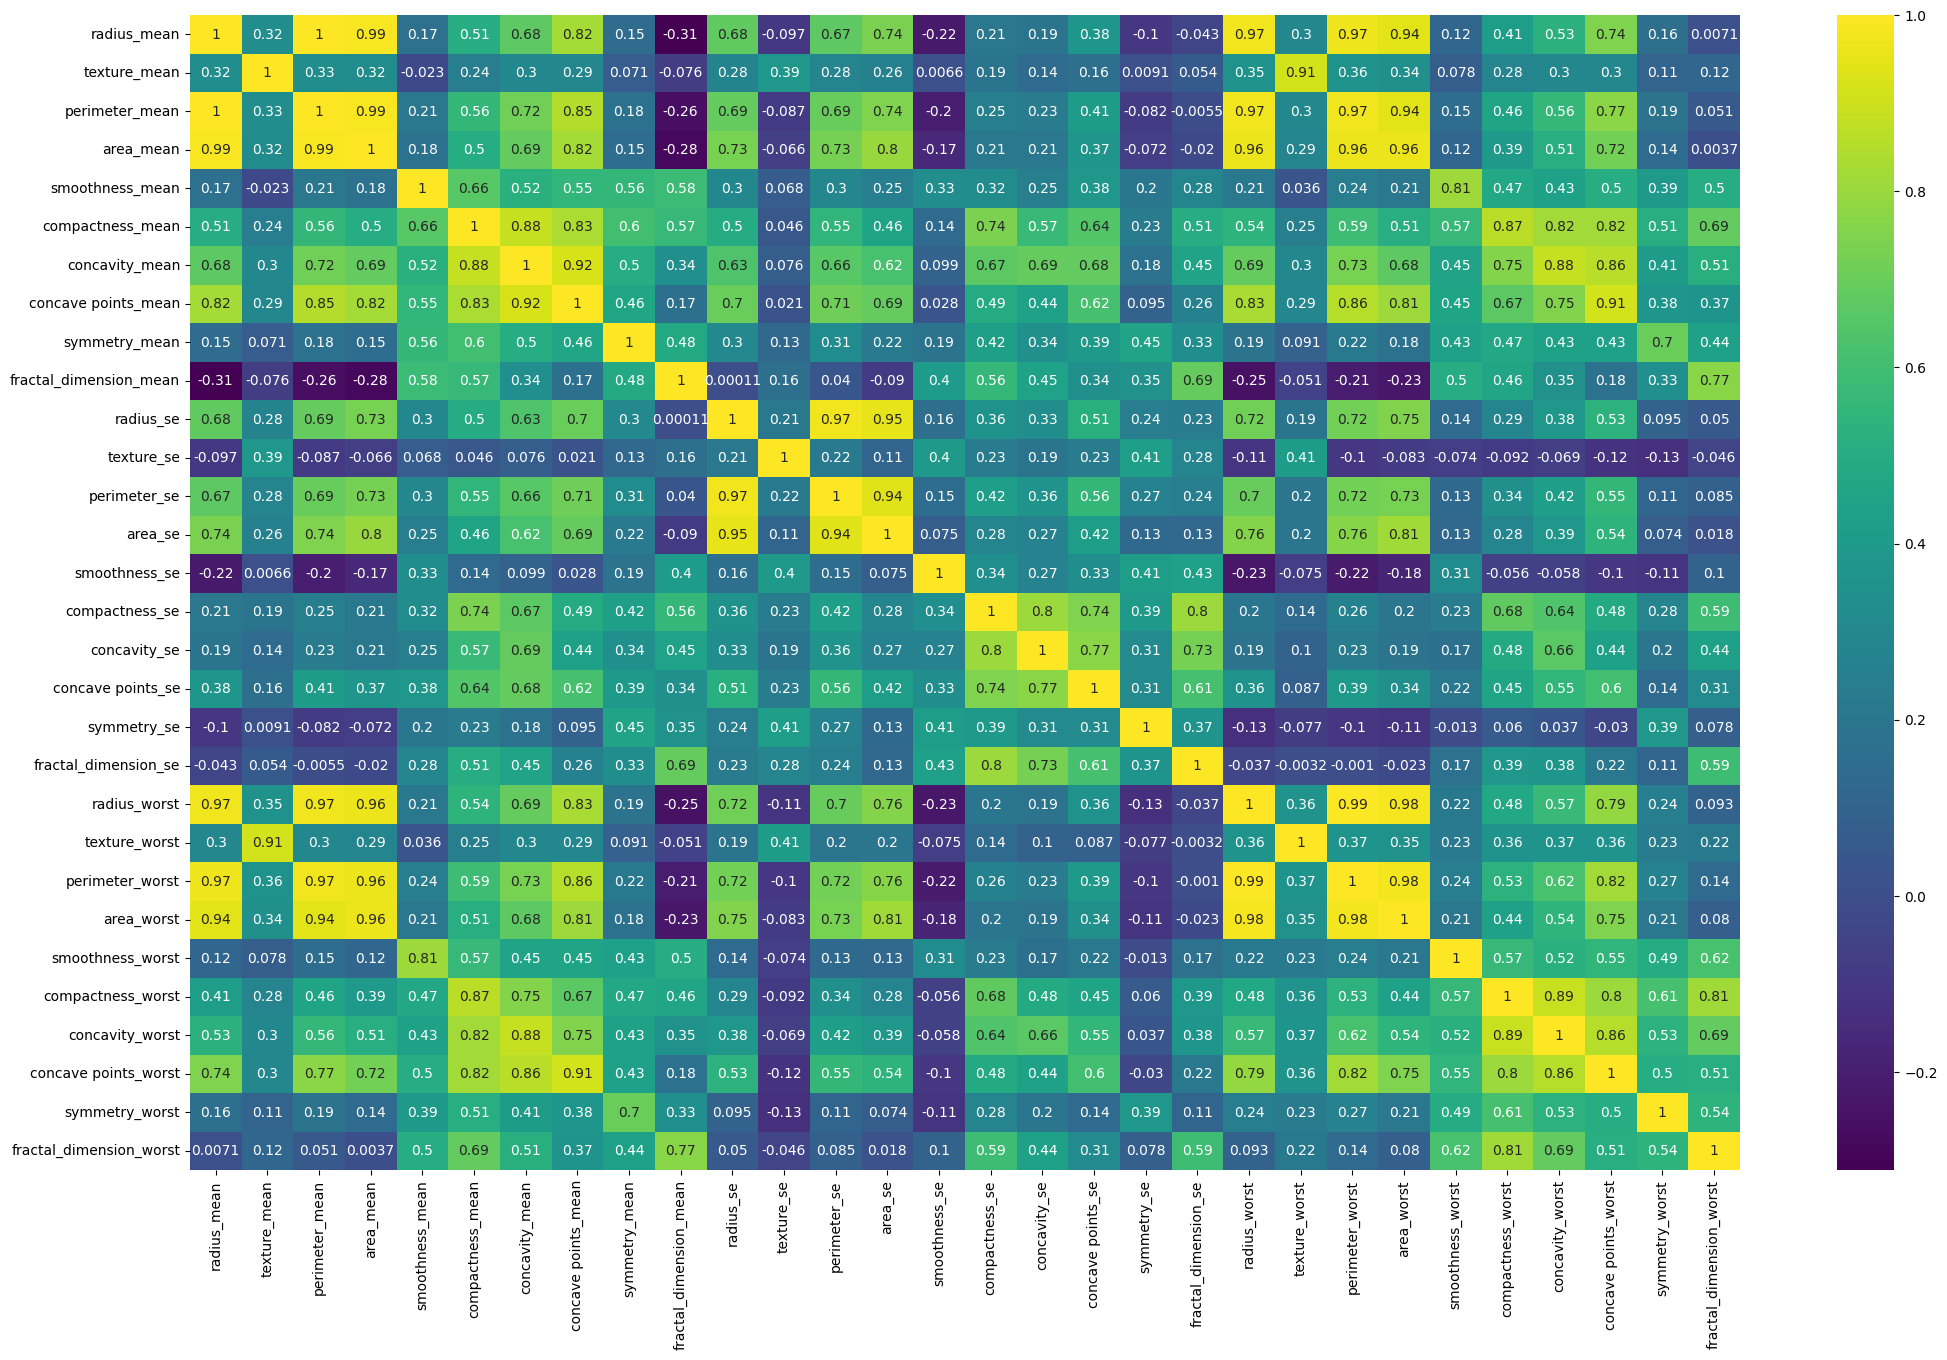

In [72]:
correlation = data.select_dtypes(include=('float64')).corr()

plt.figure(figsize=(25, 15))
sns.heatmap(correlation, annot = True, cmap = 'viridis')

In [80]:
# build a logistic model
# define dependent and independent variables
y = data['diagnosis_binary']
# X = data[['radius_mean', 'te']]
X = data[['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean']]

X_with_const = sm.add_constant(X)

# fit model 
log_model = sm.Logit(y, X_with_const).fit()

# print summary
print(log_model.summary())

Optimization terminated successfully.
         Current function value: 0.148665
         Iterations 10
                           Logit Regression Results                           
Dep. Variable:       diagnosis_binary   No. Observations:                  569
Model:                          Logit   Df Residuals:                      562
Method:                           MLE   Df Model:                            6
Date:                Wed, 30 Apr 2025   Pseudo R-squ.:                  0.7749
Time:                        01:41:55   Log-Likelihood:                -84.590
converged:                       True   LL-Null:                       -375.72
Covariance Type:            nonrobust   LLR p-value:                1.563e-122
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const              -12.5056      8.409     -1.487      0.137     -28.988       3.976
radius_mea

In [81]:
# Calculate odds ratios
print("\nOdds Ratios:")
odds_ratios = pd.DataFrame({
    'OR': log_model.params.apply(np.exp),
    '2.5%': np.exp(log_model.conf_int()[0]),
    '97.5%': np.exp(log_model.conf_int()[1])
})
print(odds_ratios)


Odds Ratios:
                            OR          2.5%         97.5%
const             3.705791e-06  2.575616e-13  5.331884e+01
radius_mean       1.107357e-03  2.276359e-06  5.386843e-01
texture_mean      1.439428e+00  1.279641e+00  1.619168e+00
perimeter_mean    1.994355e+00  8.417065e-01  4.725463e+00
area_mean         1.042530e+00  1.014752e+00  1.071069e+00
smoothness_mean   3.253265e+52  1.590551e+32  6.654129e+72
compactness_mean  4.682751e-02  1.275965e-14  1.718555e+11


In [84]:
# Model evaluation metrics
print("\nClassification Report:")
# Predict probabilities
y_pred_proba = log_model.predict(X_with_const)
# Convert probabilities to binary predictions using 0.5 threshold
y_pred = (y_pred_proba >= 0.5).astype(int)

# Calculate metrics manually
tp = np.sum((y == 1) & (y_pred == 1))
tn = np.sum((y == 0) & (y_pred == 0))
fp = np.sum((y == 0) & (y_pred == 1))
fn = np.sum((y == 1) & (y_pred == 0))

# Calculate evaluation metrics
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
f1_score = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall/Sensitivity: {recall:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"F1 Score: {f1_score:.4f}")



Classification Report:
Accuracy: 0.9315
Precision: 0.9220
Recall/Sensitivity: 0.8915
Specificity: 0.9552
F1 Score: 0.9065


In [85]:
# Confusion Matrix
conf_matrix = np.array([[tn, fp], [fn, tp]])
print("\nConfusion Matrix:")
print(conf_matrix)


Confusion Matrix:
[[341  16]
 [ 23 189]]


Text(0.5, 1.0, 'ROC Curve')

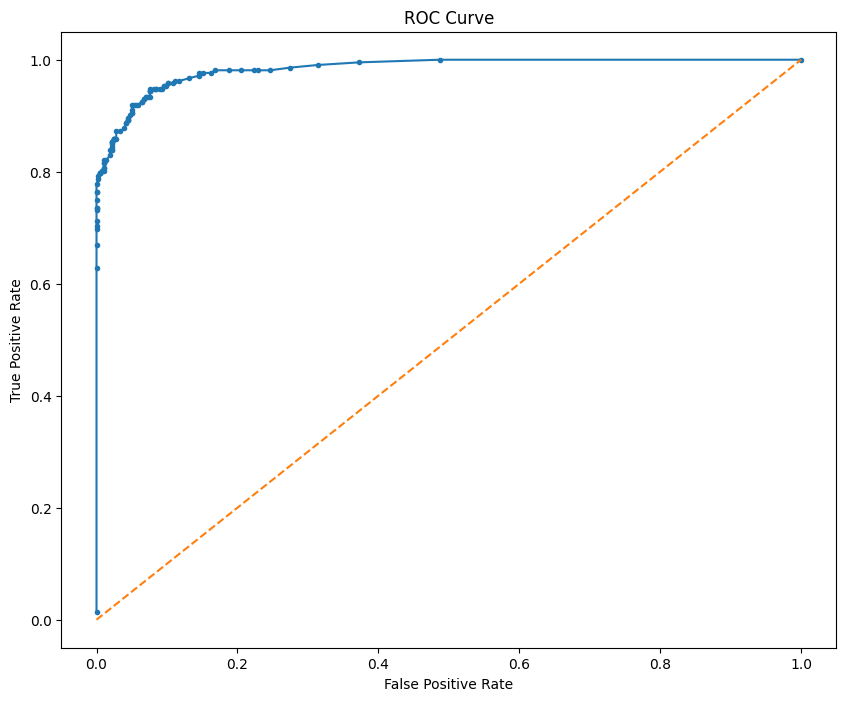

In [87]:
# Plot ROC curve
plt.figure(figsize=(10, 8))
fpr, tpr, thresholds = [], [], []
for threshold in np.arange(0, 1.01, 0.01):
    y_pred_temp = (y_pred_proba >= threshold).astype(int)
    fp = np.sum((y == 0) & (y_pred_temp == 1))
    tp = np.sum((y == 1) & (y_pred_temp == 1))
    fn = np.sum((y == 1) & (y_pred_temp == 0))
    tn = np.sum((y == 0) & (y_pred_temp == 0))
    
    fpr.append(fp / (fp + tn) if (fp + tn) > 0 else 0)
    tpr.append(tp / (tp + fn) if (tp + fn) > 0 else 0)
    thresholds.append(threshold)

plt.plot(fpr, tpr, marker='.')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')